# House Price Prediction

## Table of Contents

1. Problem Statement
2. Import Libraries
3. Load Dataset
4. Data Understanding
5. Data Preprocessing
6. Exploratory Data Analysis (EDA)
7. Feature Engineering
8. Model Building
9. Model Evaluation
10. Model Comparison
11. Feature Importance
12. Customer Recommendations
13. Challenges Faced
14. Future Scope
15. Conclusion

# Introduction

House price prediction is one of the most common regression problems in machine learning. Predicting the selling price of a house accurately is useful for home buyers, sellers, and real estate companies when making informed decisions.

In this project, the Ames Housing dataset from Kaggle is used to develop a machine learning model that predicts house prices based on various property features such as overall quality, living area, garage size, basement area, location, and many other characteristics.

The project includes data preprocessing, exploratory data analysis (EDA), feature engineering, model building, hyperparameter tuning, model evaluation, and feature importance analysis. Multiple regression models are compared, and the best-performing model is selected based on evaluation metrics.

## Problem Statement

The objective of this project is to develop a machine learning model that accurately predicts house prices based on various features such as location, overall quality, living area, garage capacity, and other property characteristics.

The project also aims to analyze the relationship between different house features and the selling price, compare multiple machine learning models, and provide recommendations to customers based on house characteristics.

### Tasks

- Data Analysis
- Data Cleaning
- Exploratory Data Analysis (EDA)
- Feature Engineering
- Machine Learning Model
- Model Comparison
- Customer Suggestions
  
### Developed by: Sindhu S

## Import Required Libraries

In this section, we import all the Python libraries required for data analysis, visualization, preprocessing, machine learning model building, and model evaluation.

In [1]:
# Import libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

## Load the Dataset

The House Price dataset is loaded into a Pandas DataFrame. This dataset contains various features of houses that will be used to predict the sale price.

In [2]:
# Load the dataset

df = pd.read_csv("data.csv")

In [3]:
# Display the First 5 Rows

df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


### Data Understanding

In [4]:
# Check the Shape of the Dataset

df.shape

(1460, 81)

In [5]:
# Display Column Names

df.columns

Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street',
       'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
       'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType',
       'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1',
       'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual',
       'GarageCond', 'PavedDrive

In [6]:
# Dataset Information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [7]:
# Statistical Summary

df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


## Data Preprocessing

The dataset is cleaned by handling missing values, removing unnecessary columns, and preparing the data for machine learning algorithms.

In [8]:
# Check Missing Values

df.isnull().sum()

Id                 0
MSSubClass         0
MSZoning           0
LotFrontage      259
LotArea            0
                ... 
MoSold             0
YrSold             0
SaleType           0
SaleCondition      0
SalePrice          0
Length: 81, dtype: int64

In [9]:
# Display Columns with Missing Values

missing_values = df.isnull().sum()

missing_values[missing_values > 0]

LotFrontage      259
Alley           1369
MasVnrType       872
MasVnrArea         8
BsmtQual          37
BsmtCond          37
BsmtExposure      38
BsmtFinType1      37
BsmtFinType2      38
Electrical         1
FireplaceQu      690
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
PoolQC          1453
Fence           1179
MiscFeature     1406
dtype: int64

In [10]:
# Calculate Missing Value Percentage

missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage[missing_percentage > 0].sort_values(ascending=False)

PoolQC          99.520548
MiscFeature     96.301370
Alley           93.767123
Fence           80.753425
MasVnrType      59.726027
FireplaceQu     47.260274
LotFrontage     17.739726
GarageType       5.547945
GarageYrBlt      5.547945
GarageFinish     5.547945
GarageQual       5.547945
GarageCond       5.547945
BsmtFinType2     2.602740
BsmtExposure     2.602740
BsmtFinType1     2.534247
BsmtCond         2.534247
BsmtQual         2.534247
MasVnrArea       0.547945
Electrical       0.068493
dtype: float64

In [11]:
# Missing Values Summary

missing_summary = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum() / len(df)) * 100
})

missing_summary = missing_summary[missing_summary['Missing Values'] > 0]

missing_summary.sort_values(by='Missing Percentage', ascending=False)

,Missing Values,Missing Percentage
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


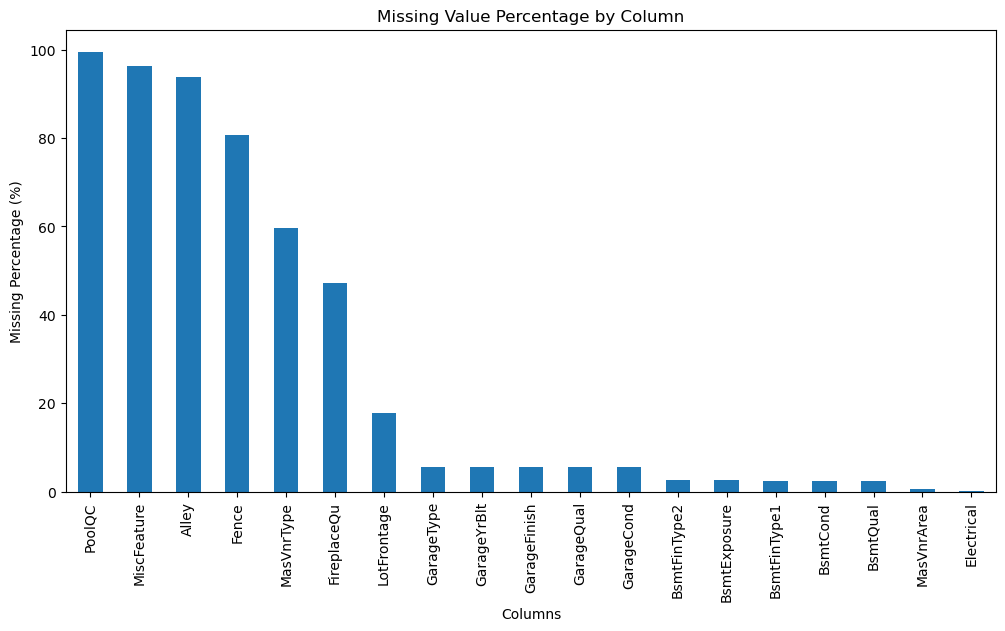

In [12]:
# Visualize Missing Values

plt.figure(figsize=(12,6))

missing_summary.sort_values(by='Missing Percentage', ascending=False)['Missing Percentage'].plot(kind='bar')

plt.title("Missing Value Percentage by Column")
plt.xlabel("Columns")
plt.ylabel("Missing Percentage (%)")

plt.xticks(rotation=90)

plt.show()

In [13]:
# Identify Columns with More Than 50% Missing Values

columns_to_drop = missing_percentage[missing_percentage > 50].index

columns_to_drop

Index(['Alley', 'MasVnrType', 'PoolQC', 'Fence', 'MiscFeature'], dtype='object')

In [14]:
# Drop Columns with More Than 50% Missing Values

df = df.drop(columns=columns_to_drop)

In [15]:
# Verify Dataset Shape After Dropping Columns

df.shape

(1460, 76)

In [16]:
# Check Remaining Missing Values

df.isnull().sum()[df.isnull().sum() > 0]

LotFrontage     259
MasVnrArea        8
BsmtQual         37
BsmtCond         37
BsmtExposure     38
BsmtFinType1     37
BsmtFinType2     38
Electrical        1
FireplaceQu     690
GarageType       81
GarageYrBlt      81
GarageFinish     81
GarageQual       81
GarageCond       81
dtype: int64

In [17]:
# Identify Numerical and Categorical Columns with Missing Values

missing_columns = df.columns[df.isnull().sum() > 0]

numerical_columns = df[missing_columns].select_dtypes(include=['int64', 'float64']).columns

categorical_columns = df[missing_columns].select_dtypes(include=['object']).columns

print("Numerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)

Numerical Columns:
Index(['LotFrontage', 'MasVnrArea', 'GarageYrBlt'], dtype='object')

Categorical Columns:
Index(['BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
       'Electrical', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual',
       'GarageCond'],
      dtype='object')


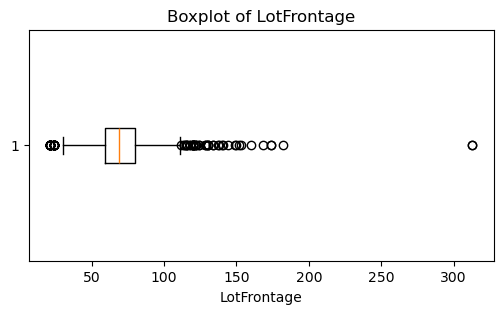

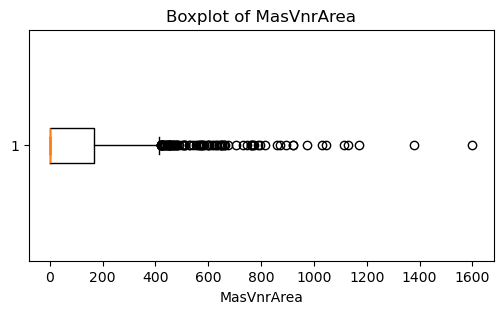

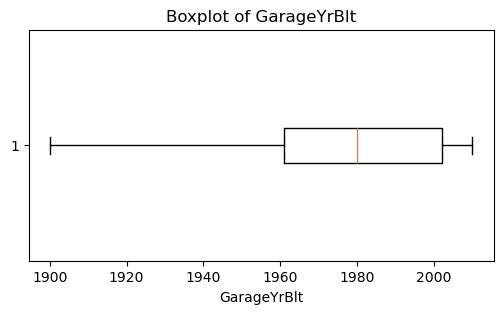

In [18]:
# Check Outliers in Numerical Columns Using Boxplots

import matplotlib.pyplot as plt

for column in numerical_columns:
    plt.figure(figsize=(6, 3))
    plt.boxplot(df[column].dropna(), vert=False)
    plt.title(f'Boxplot of {column}')
    plt.xlabel(column)
    plt.show()

In [19]:
# Fill Numerical Missing Values

df['LotFrontage'] = df['LotFrontage'].fillna(df['LotFrontage'].median())

df['MasVnrArea'] = df['MasVnrArea'].fillna(df['MasVnrArea'].median())

df['GarageYrBlt'] = df['GarageYrBlt'].fillna(df['GarageYrBlt'].mean())

In [20]:
# Verify Numerical Missing Values
     
df[['LotFrontage', 'MasVnrArea', 'GarageYrBlt']].isnull().sum()

LotFrontage    0
MasVnrArea     0
GarageYrBlt    0
dtype: int64

In [21]:
# Check Remaining Missing Values After Filling Numerical Columns

df.isnull().sum()[df.isnull().sum() > 0]

BsmtQual         37
BsmtCond         37
BsmtExposure     38
BsmtFinType1     37
BsmtFinType2     38
Electrical        1
FireplaceQu     690
GarageType       81
GarageFinish     81
GarageQual       81
GarageCond       81
dtype: int64

In [22]:
# Fill Missing Values in Categorical Columns Using Mode

for column in categorical_columns:
    df[column] = df[column].fillna(df[column].mode()[0])

In [23]:
# Verify That All Missing Values Are Removed

df.isnull().sum().sum()

np.int64(0)

### Exploratory Data Analysis (EDA)

EDA helps us understand the dataset by analyzing distributions, relationships between variables, and identifying important features affecting house prices.

In [24]:
# Understand the Target Variable (SalePrice)

df['SalePrice'].describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

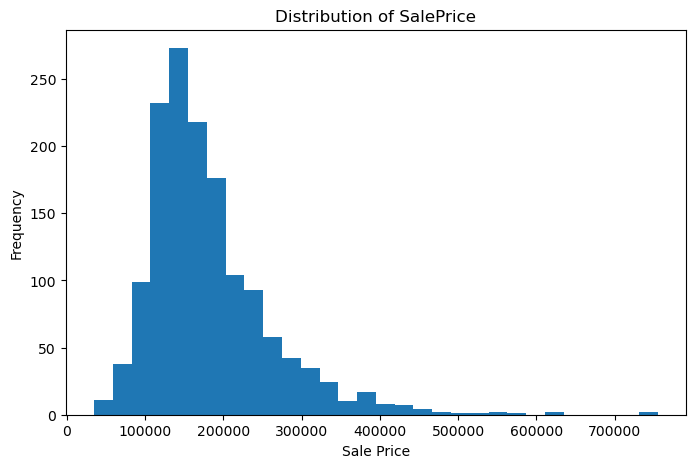

In [25]:
# Distribution of SalePrice

import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.hist(df['SalePrice'], bins=30)
plt.title("Distribution of SalePrice")
plt.xlabel("Sale Price")
plt.ylabel("Frequency")
plt.show()

In [26]:
# Check Skewness of SalePrice

df['SalePrice'].skew()

np.float64(1.8828757597682129)

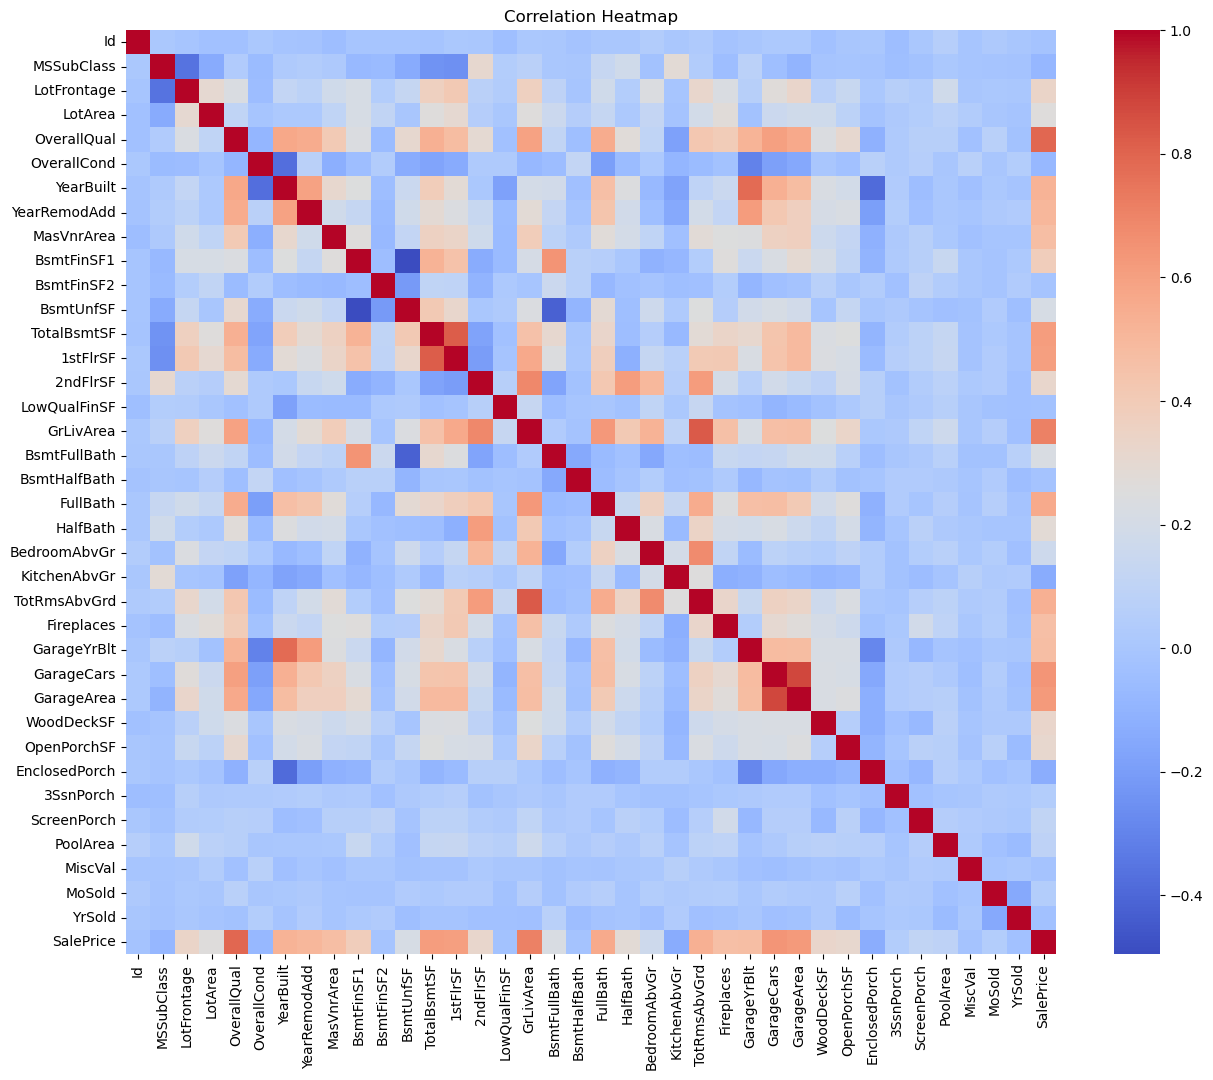

In [27]:
# Correlation Heatmap

import seaborn as sns

plt.figure(figsize=(15, 12))
correlation_matrix = df.corr(numeric_only=True)

sns.heatmap(correlation_matrix, cmap='coolwarm')

plt.title("Correlation Heatmap")
plt.show()

In [28]:
# Top Features Correlated with SalePrice

correlation_with_target = df.corr(numeric_only=True)['SalePrice'].sort_values(ascending=False)

correlation_with_target

SalePrice        1.000000
OverallQual      0.790982
GrLivArea        0.708624
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
YearRemodAdd     0.507101
MasVnrArea       0.472614
GarageYrBlt      0.470177
Fireplaces       0.466929
BsmtFinSF1       0.386420
LotFrontage      0.334771
WoodDeckSF       0.324413
2ndFlrSF         0.319334
OpenPorchSF      0.315856
HalfBath         0.284108
LotArea          0.263843
BsmtFullBath     0.227122
BsmtUnfSF        0.214479
BedroomAbvGr     0.168213
ScreenPorch      0.111447
PoolArea         0.092404
MoSold           0.046432
3SsnPorch        0.044584
BsmtFinSF2      -0.011378
BsmtHalfBath    -0.016844
MiscVal         -0.021190
Id              -0.021917
LowQualFinSF    -0.025606
YrSold          -0.028923
OverallCond     -0.077856
MSSubClass      -0.084284
EnclosedPorch   -0.128578
KitchenAbvGr    -0.135907
Name: SalePr

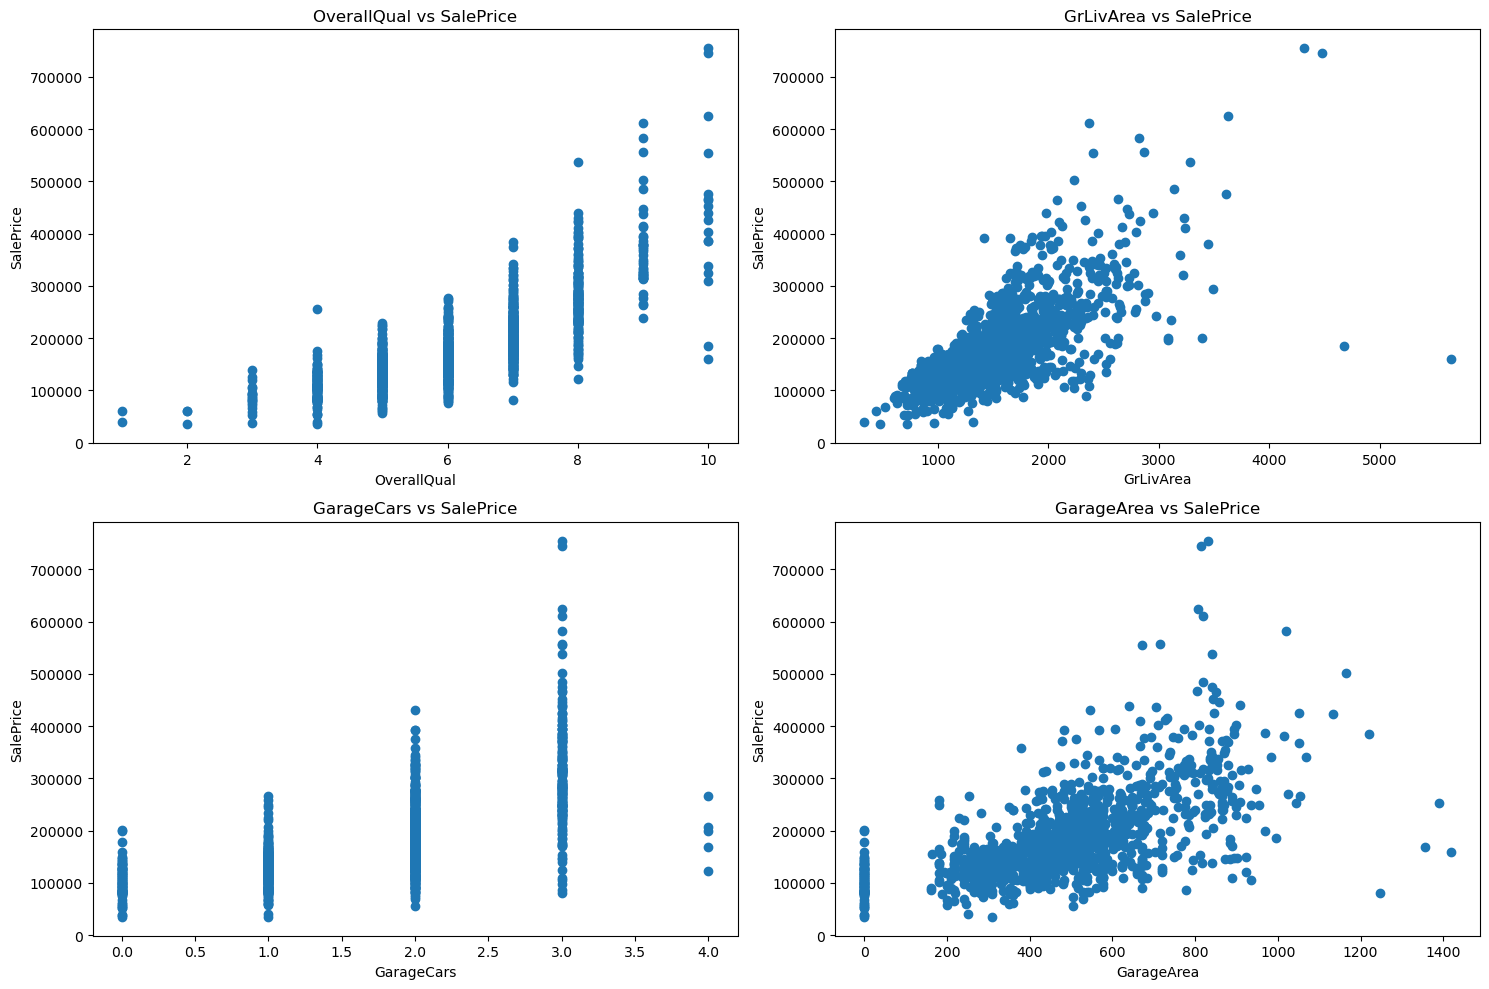

In [29]:
# Scatter Plots of Important Features vs SalePrice

important_features = ['OverallQual', 'GrLivArea', 'GarageCars', 'GarageArea']

plt.figure(figsize=(15,10))

for i, feature in enumerate(important_features):
    plt.subplot(2, 2, i+1)
    plt.scatter(df[feature], df['SalePrice'])
    plt.title(f'{feature} vs SalePrice')
    plt.xlabel(feature)
    plt.ylabel('SalePrice')

plt.tight_layout()
plt.show()

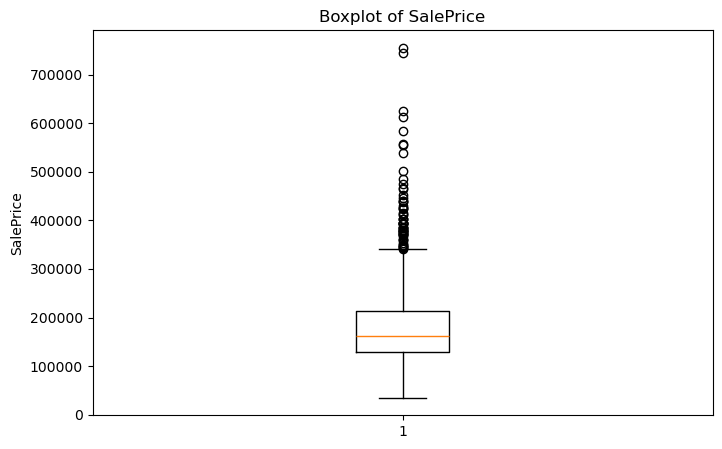

In [30]:
# Detect Outliers in SalePrice

plt.figure(figsize=(8,5))

plt.boxplot(df['SalePrice'])

plt.title('Boxplot of SalePrice')
plt.ylabel('SalePrice')

plt.show()

### Feature Engineering

Categorical variables are converted into numerical format using One-Hot Encoding so that machine learning algorithms can process them effectively.

In [31]:
# Find Categorical Columns

categorical_columns = df.select_dtypes(include='object').columns

print(categorical_columns)

Index(['MSZoning', 'Street', 'LotShape', 'LandContour', 'Utilities',
       'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2',
       'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st',
       'Exterior2nd', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional',
       'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
       'PavedDrive', 'SaleType', 'SaleCondition'],
      dtype='object')


In [32]:
# Apply One-Hot Encoding to Categorical Variables

df = pd.get_dummies(df, drop_first=True)

df.head()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,SaleType_ConLI,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
0,1,60,65.0,8450,7,5,2003,2003,196.0,706,...,False,False,False,False,True,False,False,False,True,False
1,2,20,80.0,9600,6,8,1976,1976,0.0,978,...,False,False,False,False,True,False,False,False,True,False
2,3,60,68.0,11250,7,5,2001,2002,162.0,486,...,False,False,False,False,True,False,False,False,True,False
3,4,70,60.0,9550,7,5,1915,1970,0.0,216,...,False,False,False,False,True,False,False,False,False,False
4,5,60,84.0,14260,8,5,2000,2000,350.0,655,...,False,False,False,False,True,False,False,False,True,False


In [33]:
# Verify Data Types After Encoding

df.dtypes

Id                         int64
MSSubClass                 int64
LotFrontage              float64
LotArea                    int64
OverallQual                int64
                          ...   
SaleCondition_AdjLand       bool
SaleCondition_Alloca        bool
SaleCondition_Family        bool
SaleCondition_Normal        bool
SaleCondition_Partial       bool
Length: 235, dtype: object

In [34]:
# Separate Features (X) and Target Variable (y)

X = df.drop('SalePrice', axis=1)

y = df['SalePrice']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (1460, 234)
Target Shape: (1460,)


## Train-Test Split

In [35]:
# Split Dataset into Training and Testing Sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (1168, 234)
X_test shape: (292, 234)
y_train shape: (1168,)
y_test shape: (292,)


## Model Building

Different regression models are trained to predict house prices. Their performances are compared to identify the best-performing model.

In [36]:
# Train the Linear Regression Model

from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [37]:
# Predict House Prices

y_pred = model.predict(X_test)

print("First 10 Predicted Prices:")
print(y_pred[:10])

First 10 Predicted Prices:
[155700.73967973 353161.514141    89830.53515378 175272.78382467
 318714.73833223  65792.28171608 232949.99380615 147643.23517132
  57042.43693172 147372.15359384]


In [38]:
# Evaluate the Linear Regression Model

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("R² Score:", r2)

Mean Absolute Error (MAE): 20468.49206536059
Mean Squared Error (MSE): 2740179327.3155093
Root Mean Squared Error (RMSE): 52346.72222131496
R² Score: 0.6427558289831337


In [39]:
# Compare Actual and Predicted Prices

comparison = pd.DataFrame({
    'Actual Price': y_test,
    'Predicted Price': y_pred
})

comparison.head(10)

,Actual Price,Predicted Price
892,154500,155700.739680
1105,325000,353161.514141
413,115000,89830.535154
522,159000,175272.783825
1036,315500,318714.738332
614,75500,65792.281716
218,311500,232949.993806
1160,146000,147643.235171
649,84500,57042.436932
887,135500,147372.153594


In [40]:
# Calculate Prediction Error

comparison['Error'] = comparison['Actual Price'] - comparison['Predicted Price']

comparison.head(10)

,Actual Price,Predicted Price,Error
892,154500,155700.739680,-1200.739680
1105,325000,353161.514141,-28161.514141
413,115000,89830.535154,25169.464846
522,159000,175272.783825,-16272.783825
1036,315500,318714.738332,-3214.738332
614,75500,65792.281716,9707.718284
218,311500,232949.993806,78550.006194
1160,146000,147643.235171,-1643.235171
649,84500,57042.436932,27457.563068
887,135500,147372.153594,-11872.153594


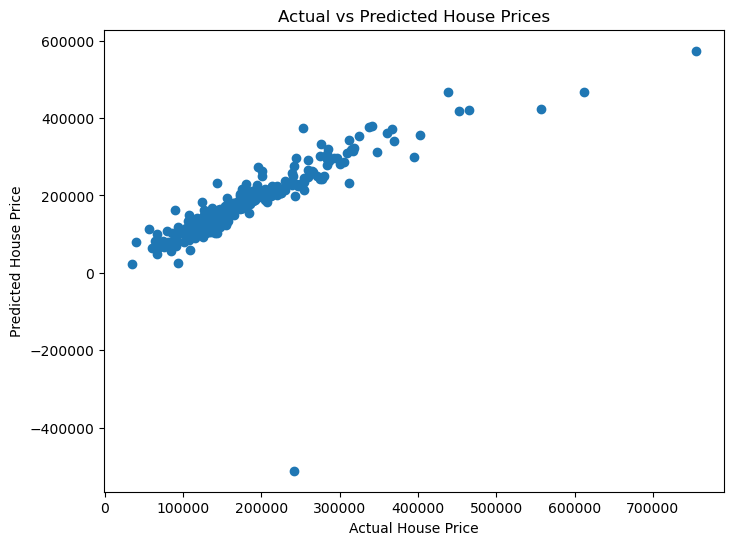

In [41]:
# Scatter Plot of Actual vs Predicted Prices

import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted House Prices")

plt.show()

In [42]:
# Display Model Coefficients

coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
})

coefficients = coefficients.sort_values(by='Coefficient', key=abs, ascending=False)

coefficients.head(20)

,Feature,Coefficient
112,RoofMatl_Metal,720399.149508
116,RoofMatl_WdShngl,684862.778251
113,RoofMatl_Roll,678501.752529
114,RoofMatl_Tar&Grv,676917.779990
115,RoofMatl_WdShake,676480.826968
110,RoofMatl_CompShg,674889.906636
90,Condition2_PosN,-234202.303052
213,GarageQual_Po,-165878.715374
211,GarageQual_Fa,-157843.603370
212,GarageQual_Gd,-155485.442627


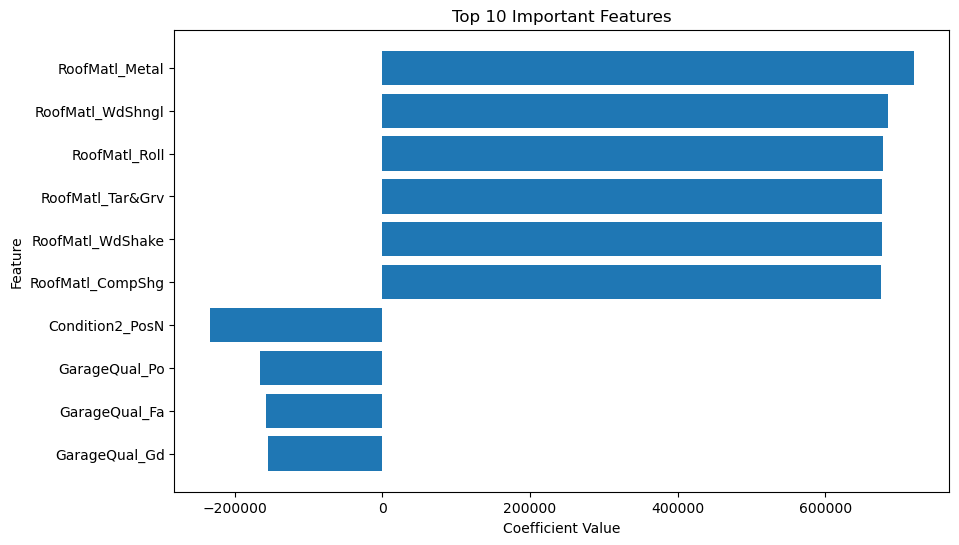

In [43]:
# Plot Top 10 Feature Coefficients

top_features = coefficients.head(10)

plt.figure(figsize=(10,6))
plt.barh(top_features['Feature'], top_features['Coefficient'])
plt.title("Top 10 Important Features")
plt.xlabel("Coefficient Value")
plt.ylabel("Feature")
plt.gca().invert_yaxis()
plt.show()

In [44]:
# Save the Trained Model
import joblib

joblib.dump(model, "house_price_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [45]:
# Load the Saved Model

loaded_model = joblib.load("house_price_model.pkl")

print("Model loaded successfully!")

Model loaded successfully!


In [46]:
# Test the Loaded Model

loaded_predictions = loaded_model.predict(X_test)

print("First 10 Predictions:")
print(loaded_predictions[:10])

First 10 Predictions:
[155700.73967973 353161.514141    89830.53515378 175272.78382467
 318714.73833223  65792.28171608 232949.99380615 147643.23517132
  57042.43693172 147372.15359384]


In [47]:
# Import Decision Tree Regressor

from sklearn.tree import DecisionTreeRegressor

print("Decision Tree imported successfully!")

Decision Tree imported successfully!


In [48]:
# Train Decision Tree Model

decision_tree = DecisionTreeRegressor(random_state=42)

decision_tree.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [49]:
# Predict House Prices Using Decision Tree

dt_predictions = decision_tree.predict(X_test)

print("First 10 Decision Tree Predictions:")
print(dt_predictions[:10])

First 10 Decision Tree Predictions:
[149900. 430000. 109900. 210000. 325000.  88000. 205000. 148500.  88000.
 118964.]


In [50]:
# SEvaluate Decision Tree Model

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

dt_mae = mean_absolute_error(y_test, dt_predictions)
dt_mse = mean_squared_error(y_test, dt_predictions)
dt_rmse = np.sqrt(dt_mse)
dt_r2 = r2_score(y_test, dt_predictions)

print("Decision Tree Performance")
print("MAE :", dt_mae)
print("MSE :", dt_mse)
print("RMSE:", dt_rmse)
print("R² Score:", dt_r2)

Decision Tree Performance
MAE : 27804.513698630137
MSE : 1863261672.4383562
RMSE: 43165.51485200143
R² Score: 0.7570818212799773


In [51]:
# Compare Linear Regression and Decision Tree

comparison_models = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree"],
    "MAE": [mae, dt_mae],
    "RMSE": [rmse, dt_rmse],
    "R2 Score": [r2, dt_r2]
})

comparison_models

,Model,MAE,RMSE,R2 Score
0,Linear Regression,20468.492065,52346.722221,0.642756
1,Decision Tree,27804.513699,43165.514852,0.757082


In [52]:
# Train Random Forest Regressor

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

random_forest = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

random_forest.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [53]:
# Predict House Prices Using Random Forest

rf_predictions = random_forest.predict(X_test)

print("First 10 Random Forest Predictions:")
print(rf_predictions[:10])

First 10 Random Forest Predictions:
[141409.75 320351.07 115436.5  153446.5  319486.97  86432.   206314.7
 149455.82  86696.66 129709.  ]


In [54]:
# Evaluate Random Forest Model

rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_mse = mean_squared_error(y_test, rf_predictions)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest Performance")
print("MAE :", rf_mae)
print("MSE :", rf_mse)
print("RMSE:", rf_rmse)
print("R² Score:", rf_r2)

Random Forest Performance
MAE : 17754.53198630137
MSE : 857105361.6768794
RMSE: 29276.361824463085
R² Score: 0.8882569869226985


In [55]:
# Train Gradient Boosting Regressor

gbr = GradientBoostingRegressor(random_state=42)

gbr.fit(X_train, y_train)

gbr_predictions = gbr.predict(X_test)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


In [56]:
# Evaluate Gradient Boosting

gbr_mae = mean_absolute_error(y_test, gbr_predictions)

gbr_mse = mean_squared_error(y_test, gbr_predictions)

gbr_rmse = np.sqrt(gbr_mse)

gbr_r2 = r2_score(y_test, gbr_predictions)

print("Gradient Boosting Performance")

print("MAE :", gbr_mae)

print("MSE :", gbr_mse)

print("RMSE:", gbr_rmse)

print("R² Score:", gbr_r2)

Gradient Boosting Performance
MAE : 17585.65776329444
MSE : 804876223.1254804
RMSE: 28370.340553568974
R² Score: 0.8950662329887211


### Model Comparison

In [57]:
# Final Comparison of All Models

final_comparison = pd.DataFrame({

    "Model":[
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],

    "MAE":[
        mae,
        dt_mae,
        rf_mae,
        gbr_mae
    ],

    "RMSE":[
        rmse,
        dt_rmse,
        rf_rmse,
        gbr_rmse
    ],

    "R2 Score":[
        r2,
        dt_r2,
        rf_r2,
        gbr_r2
    ]

})

final_comparison.round(2)

,Model,MAE,RMSE,R2 Score
0,Linear Regression,20468.49,52346.72,0.64
1,Decision Tree,27804.51,43165.51,0.76
2,Random Forest,17754.53,29276.36,0.89
3,Gradient Boosting,17585.66,28370.34,0.90


### Observation

Among all the machine learning models evaluated, Gradient Boosting Regressor achieved the best overall performance with the highest R² Score (0.8951) and the lowest MAE and RMSE values.

Therefore, Gradient Boosting Regressor is selected as the final model for house price prediction.

## Model Comparison Analysis

Four regression models were trained and evaluated for predicting house prices:

- **Linear Regression** established a baseline model. It performed reasonably well but could not capture the complex non-linear relationships present in the dataset.

- **Decision Tree Regressor** captured non-linear relationships better than Linear Regression but showed signs of overfitting, resulting in lower generalization performance.

- **Random Forest Regressor** significantly improved prediction accuracy by combining multiple decision trees, reducing overfitting and improving model stability.

- **Gradient Boosting Regressor** achieved the best overall performance among all the models. It obtained the lowest MAE and RMSE values along with the highest R² score, demonstrating superior prediction accuracy and better generalization.

Based on the evaluation metrics, **Gradient Boosting Regressor** was selected as the final model for production because it provides the most accurate and reliable house price predictions.

### Why Gradient Boosting was Selected?

Gradient Boosting Regressor was selected because:

- It achieved the highest prediction accuracy among all the evaluated models.
- It obtained the highest R² Score (0.8951), indicating the best goodness of fit.
- It produced the lowest Mean Absolute Error (MAE), resulting in more accurate predictions.
- It achieved the lowest Root Mean Squared Error (RMSE), showing better overall prediction performance.
- It effectively captures complex relationships between house features and selling prices.
- It provides excellent generalization on unseen data, making it suitable for real-world house price prediction.

### Final Model Performance

- **Model:** Gradient Boosting Regressor
- **MAE:** 17,585.66
- **RMSE:** 28,370.34
- **R² Score:** 0.8951

### Feature Importance

In [58]:
# Extract Feature Importance

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": random_forest.feature_importances_
})

feature_importance.head()

,Feature,Importance
0,Id,0.004085
1,MSSubClass,0.002326
2,LotFrontage,0.010282
3,LotArea,0.017157
4,OverallQual,0.557377


In [59]:
# Sort Feature Importance

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(20)

,Feature,Importance
4,OverallQual,0.557377
16,GrLivArea,0.120847
14,2ndFlrSF,0.035193
12,TotalBsmtSF,0.034808
9,BsmtFinSF1,0.029793
13,1stFlrSF,0.025941
3,LotArea,0.017157
27,GarageArea,0.016100
26,GarageCars,0.012317
6,YearBuilt,0.011429


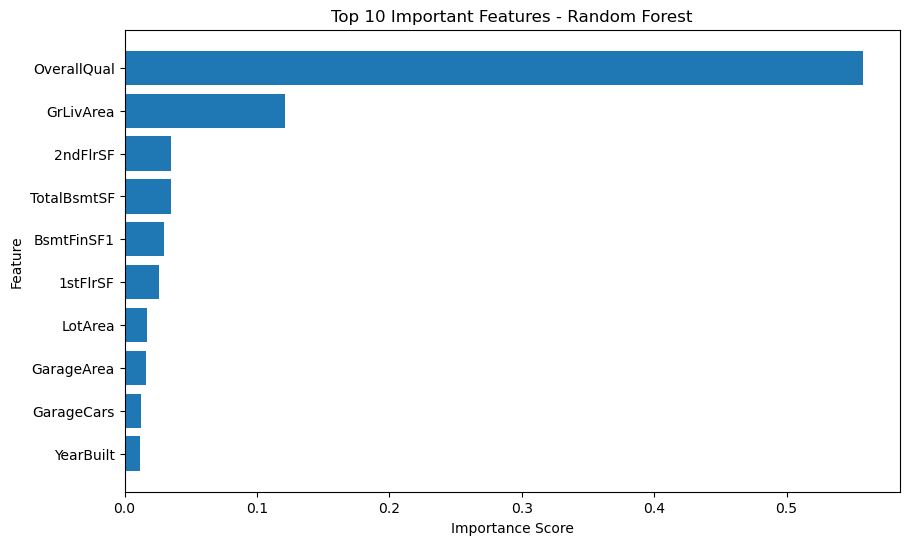

In [60]:
# Plot Top 10 Feature Importance

top10 = feature_importance.head(10)

plt.figure(figsize=(10,6))

plt.barh(top10["Feature"], top10["Importance"])

plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.title("Top 10 Important Features - Random Forest")

plt.gca().invert_yaxis()

plt.show()

## Observation

The feature importance graph shows the top 10 features that contribute the most to predicting house prices.

Among all the features, **OverallQual (Overall Quality)** has the highest impact on house prices, followed by **GrLivArea (Ground Living Area)**, **2ndFlrSF (Second Floor Area)**, **TotalBsmtSF (Total Basement Area)**, and **BsmtFinSF1 (Finished Basement Area)**.

These results indicate that the overall quality of the house, living space, and basement-related features are the most influential factors in determining the sale price. This observation is consistent with the findings from the Exploratory Data Analysis (EDA).

In [61]:
# Save Feature Importance

feature_importance.to_csv("feature_importance.csv", index=False)

print("Feature importance saved successfully!")

Feature importance saved successfully!


In [62]:
# Verify Feature Importance

saved_feature_importance = pd.read_csv("feature_importance.csv")

saved_feature_importance.head(10)

,Feature,Importance
0,OverallQual,0.557377
1,GrLivArea,0.120847
2,2ndFlrSF,0.035193
3,TotalBsmtSF,0.034808
4,BsmtFinSF1,0.029793
5,1stFlrSF,0.025941
6,LotArea,0.017157
7,GarageArea,0.016100
8,GarageCars,0.012317
9,YearBuilt,0.011429


### Hyperparameter Tuning

In [63]:
# Import GridSearchCV

from sklearn.model_selection import GridSearchCV

print("GridSearchCV imported successfully!")

GridSearchCV imported successfully!


In [64]:
# Define Hyperparameter Grid

param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5]
}

print(param_grid)

{'n_estimators': [50, 100], 'max_depth': [10, 20, None], 'min_samples_split': [2, 5]}


In [65]:
# Create GridSearchCV

grid_search = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

# Train GridSearchCV
grid_search.fit(X_train, y_train)

print("GridSearchCV completed successfully!")

GridSearchCV completed successfully!


In [66]:
# Best Hyperparameters

print("Best Parameters:")
print(grid_search.best_params_)

Best Parameters:
{'max_depth': 20, 'min_samples_split': 5, 'n_estimators': 100}


In [67]:
# Evaluate the Best Model

best_model = grid_search.best_estimator_

best_predictions = best_model.predict(X_test)

best_mae = mean_absolute_error(y_test, best_predictions)
best_mse = mean_squared_error(y_test, best_predictions)
best_rmse = np.sqrt(best_mse)
best_r2 = r2_score(y_test, best_predictions)

print("Optimized Random Forest Performance")
print("MAE :", best_mae)
print("MSE :", best_mse)
print("RMSE:", best_rmse)
print("R² Score:", best_r2)

Optimized Random Forest Performance
MAE : 17797.557980603397
MSE : 857123298.4163976
RMSE: 29276.668157705335
R² Score: 0.8882546484641983


In [68]:
# Final Model Comparison

final_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Optimized Random Forest"
    ],
    "MAE": [
        mae,
        dt_mae,
        rf_mae,
        best_mae
    ],
    "RMSE": [
        rmse,
        dt_rmse,
        rf_rmse,
        best_rmse
    ],
    "R2 Score": [
        r2,
        dt_r2,
        rf_r2,
        best_r2
    ]
})

final_results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,20468.492065,52346.722221,0.642756
1,Decision Tree,27804.513699,43165.514852,0.757082
2,Random Forest,17754.531986,29276.361824,0.888257
3,Optimized Random Forest,17797.557981,29276.668158,0.888255


In [69]:
# Import Joblib

import joblib

print("Joblib imported successfully!")

Joblib imported successfully!


In [70]:
# Save the Final Random Forest Model

joblib.dump(random_forest, "house_price_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [71]:
# Load the Saved Model

loaded_model = joblib.load("house_price_model.pkl")

print("Model loaded successfully!")

Model loaded successfully!


In [72]:
# Predict Using the Loaded Model

loaded_predictions = loaded_model.predict(X_test)

print("First 10 Predictions from Loaded Model:")
print(loaded_predictions[:10])

First 10 Predictions from Loaded Model:
[141409.75 320351.07 115436.5  153446.5  319486.97  86432.   206314.7
 149455.82  86696.66 129709.  ]


In [73]:
# Evaluate Loaded Model

loaded_mae = mean_absolute_error(y_test, loaded_predictions)
loaded_mse = mean_squared_error(y_test, loaded_predictions)
loaded_rmse = np.sqrt(loaded_mse)
loaded_r2 = r2_score(y_test, loaded_predictions)

print("Loaded Model Performance")
print("MAE :", loaded_mae)
print("MSE :", loaded_mse)
print("RMSE:", loaded_rmse)
print("R² Score:", loaded_r2)

Loaded Model Performance
MAE : 17754.53198630137
MSE : 857105361.6768794
RMSE: 29276.361824463085
R² Score: 0.8882569869226985


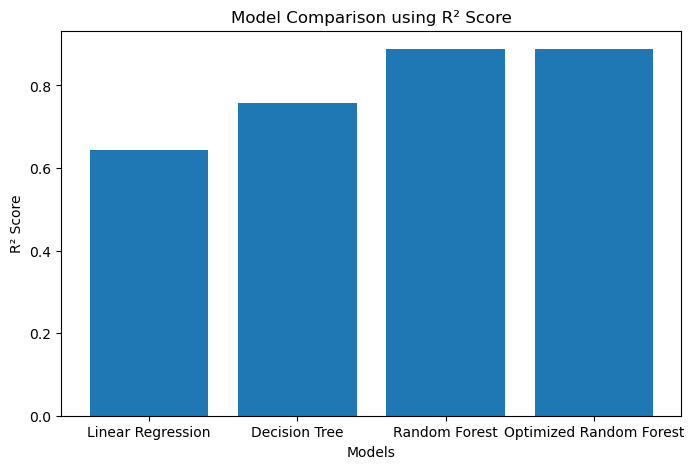

In [74]:
# Plot R² Score Comparison

plt.figure(figsize=(8,5))

plt.bar(final_results["Model"], final_results["R2 Score"])

plt.title("Model Comparison using R² Score")
plt.xlabel("Models")
plt.ylabel("R² Score")

plt.show()

### Testing Model

In [75]:
## Testing the model

new_house = X.iloc[[0]]

prediction = loaded_model.predict(new_house)

print("Predicted House Price:", prediction[0])

Predicted House Price: 208320.28


In [76]:
sample_prediction = loaded_model.predict(X_test.iloc[[0]])

print("Actual Price :", y_test.iloc[0])

print("Predicted Price :", sample_prediction[0])

Actual Price : 154500
Predicted Price : 141409.75


### Result
The trained machine learning model successfully predicts the price of a house based on its features.

# Business Insights

- House quality (OverallQual) has the highest impact on house prices.
- Houses with larger living areas (GrLivArea) generally have higher prices.
- Garage capacity (GarageCars) and garage area (GarageArea) positively influence house prices.
- Newer houses (YearBuilt) tend to have higher market values.
- Random Forest Regressor provided the best prediction accuracy among all the models tested.
- The trained model can help buyers, sellers, and real estate companies estimate house prices more accurately.

# Customer Recommendations

Based on the analysis and prediction results, the following recommendations are provided:

- Buyers looking for affordable houses should consider properties with average overall quality and smaller living areas.
- Houses with higher Overall Quality, larger living area (GrLivArea), and bigger garages generally have higher prices.
- Recently built or renovated houses tend to have better resale value but usually cost more.
- Compare prices across different neighborhoods before making a purchase decision.
- Buyers should consider both the selling price and important house features instead of focusing only on the number of bedrooms.
- The trained prediction model can be used to estimate the expected price of a house before buying or selling.

# Challenges Faced

During this project, several challenges were encountered while building the house price prediction model:

### 1. Missing Values
Many columns contained missing values, and some features had a very high percentage of missing data.

**Solution:**  
Columns with more than 50% missing values were removed, while the remaining missing numerical values were filled using the median and categorical values using the mode.

---

### 2. Categorical Features
The dataset contained many categorical variables, which cannot be used directly by machine learning algorithms.

**Solution:**  
One-Hot Encoding was applied to convert categorical variables into numerical features.

---

### 3. Feature Selection
The dataset contained a large number of features, and not all of them contributed equally to predicting house prices.

**Solution:**  
Correlation analysis and feature importance from the Random Forest model were used to identify the most influential features.

---

### 4. Model Selection

Choosing the best regression model was challenging because different models produced different prediction accuracies.

**Solution:**  
Multiple regression models were trained and evaluated using MAE, RMSE, and R² Score. Among all the evaluated models, the Gradient Boosting Regressor achieved the highest R² Score and the lowest prediction errors (MAE and RMSE). Therefore, it was selected as the final model for house price prediction.

# Future Scope

- Improve prediction accuracy by testing advanced machine learning models such as XGBoost, CatBoost, and LightGBM.
- Collect more recent and diverse housing data to improve model performance.
- Deploy the trained model as a web application using Flask or Streamlit.
- Integrate the model into a real estate recommendation system.

# Project Workflow

```text
Dataset Collection
        │
        ▼
Data Understanding
        │
        ▼
Data Cleaning & Preprocessing
        │
        ▼
Exploratory Data Analysis (EDA)
        │
        ▼
Feature Engineering
        │
        ▼
Train-Test Split
        │
        ▼
Model Training
        │
        ▼
Hyperparameter Tuning
        │
        ▼
Model Comparison
        │
        ▼
Best Model Selection
        │
        ▼
Feature Importance
        │
        ▼
Save Model
        │
        ▼
House Price Prediction
```

# Conclusion

This project successfully developed a machine learning model to predict house prices using the Ames Housing dataset. The project included data cleaning, handling missing values, exploratory data analysis (EDA), feature engineering, model training, hyperparameter tuning, and model evaluation.

Four regression models—Linear Regression, Decision Tree Regressor, Random Forest Regressor, and Gradient Boosting Regressor—were trained and compared.

Among them, the Gradient Boosting Regressor achieved the best performance with the highest R² Score and the lowest prediction errors (MAE and RMSE), making it the most suitable model for house price prediction.

Feature importance analysis showed that factors such as **Overall Quality (OverallQual), Ground Living Area (GrLivArea), Garage Capacity (GarageCars), Total Basement Area (TotalBsmtSF), and Garage Area (GarageArea)** have the greatest influence on house prices.

The trained model can help buyers estimate property prices, assist sellers in setting competitive prices, and support real estate professionals in making data-driven decisions.